# 09. 데이터 시각화 ② seaborn 활용

**AICE Associate 학습 9단계**

seaborn은 matplotlib 위에 만들어진 통계 시각화 라이브러리로, **DataFrame과 컬럼명만으로** 그래프를 그릴 수 있습니다.
시험의 데이터 분석 영역(3~4번 문항)은 대부분 seaborn 문항입니다.

### 학습 목표
1. 분포(`countplot`, `histplot`, `kdeplot`, `boxplot`, `violinplot`)를 그릴 수 있다.
2. 관계(`scatterplot`, `jointplot`, `pairplot`, `heatmap`, `barplot`, `lineplot`)를 그릴 수 있다.
3. `hue`로 그룹을 구분하고, `ax`로 subplots에 배치할 수 있다.

### seaborn 공통 문법
```python
sns.그래프종류(data=데이터프레임, x='컬럼', y='컬럼', hue='구분컬럼', ax=axes[0])
```

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


In [2]:
titanic = pd.read_csv('titanic.csv')
cust = pd.read_csv('cust_data.csv')
titanic.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


---
## 1. 범주형 분포: `countplot` ★

범주별 **개수**를 막대로 보여줍니다. (샘플 문항: "목적지 주소1의 분포를 countplot으로 그리고 가장 많은 값을 답안에 저장")

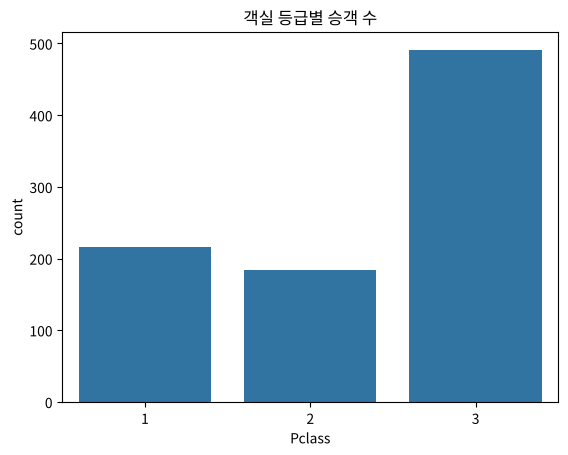

In [3]:
sns.countplot(data=titanic, x='Pclass')
plt.title('객실 등급별 승객 수')
plt.show()

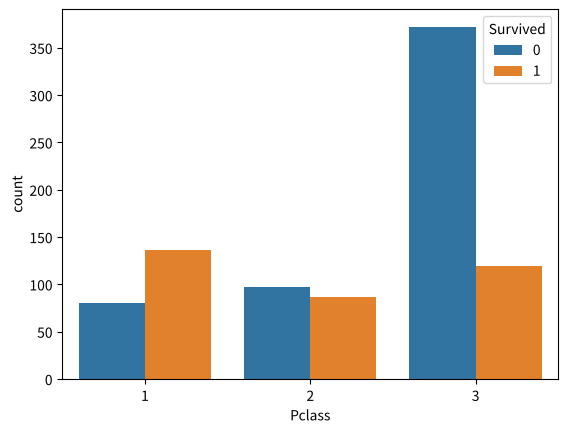

In [4]:
# hue: 그룹별로 색을 나눔
sns.countplot(data=titanic, x='Pclass', hue='Survived')
plt.show()

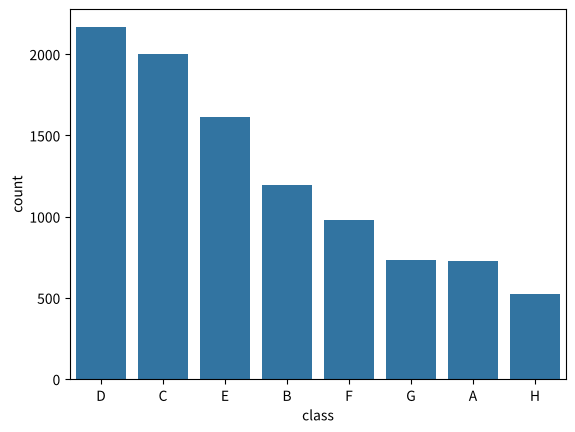

가장 많은 등급: D


In [5]:
# order: 막대 순서 지정 (많은 순)
sns.countplot(data=cust, x='class', order=cust['class'].value_counts().index)
plt.show()
print("가장 많은 등급:", cust['class'].value_counts().idxmax())

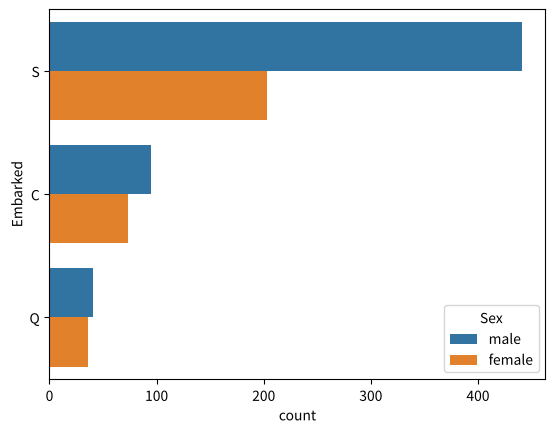

In [6]:
# y= 로 주면 가로 막대
sns.countplot(data=titanic, y='Embarked', hue='Sex')
plt.show()

---
## 2. 수치형 분포: `histplot`, `kdeplot` ★

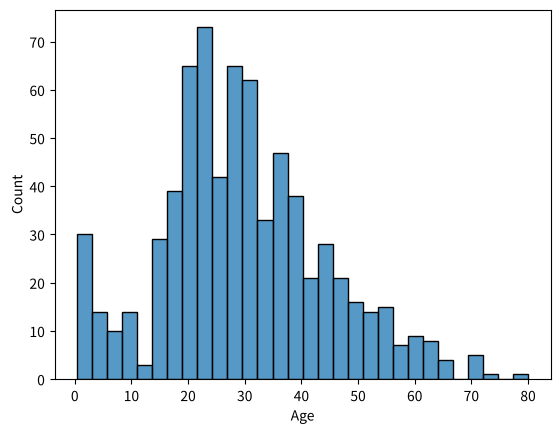

In [7]:
sns.histplot(data=titanic, x='Age', bins=30)
plt.show()

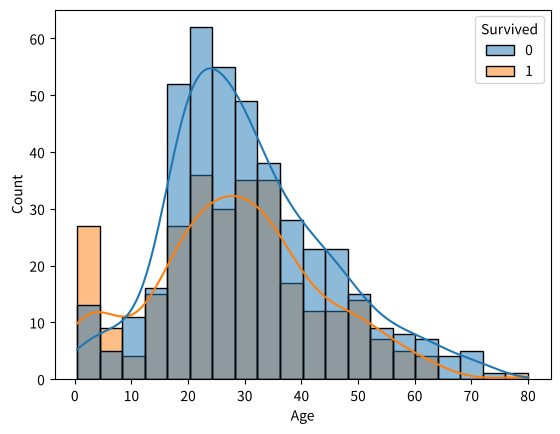

In [8]:
sns.histplot(data=titanic, x='Age', hue='Survived', kde=True)   # kde: 밀도 곡선 추가
plt.show()

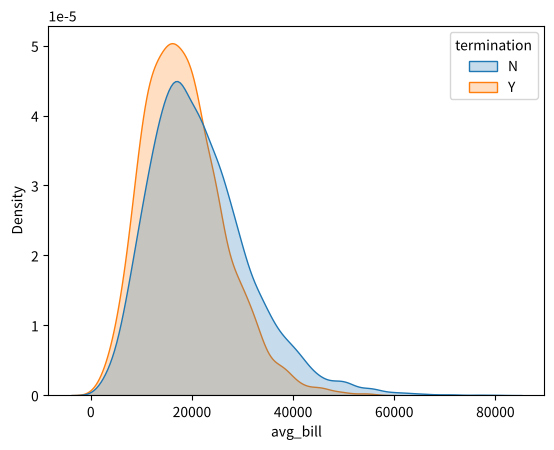

In [9]:
sns.kdeplot(data=cust, x='avg_bill', hue='termination', fill=True, common_norm=False)
plt.show()

---
## 3. 그룹별 분포 비교: `boxplot` ★, `violinplot`

boxplot은 **이상치 탐지**에 쓰입니다. (샘플 문항: "Grade별 FE_points_winery 분포를 boxplot으로")

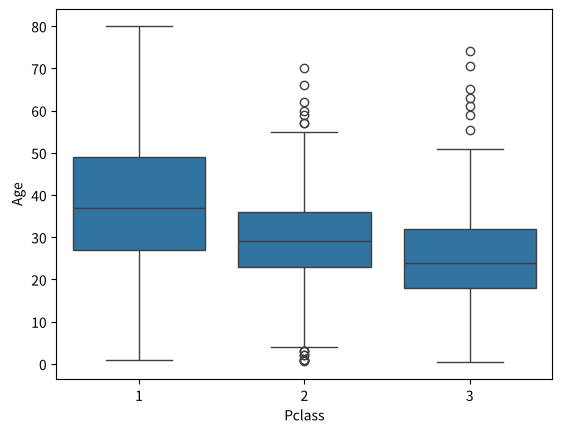

In [10]:
sns.boxplot(data=titanic, x='Pclass', y='Age')
plt.show()

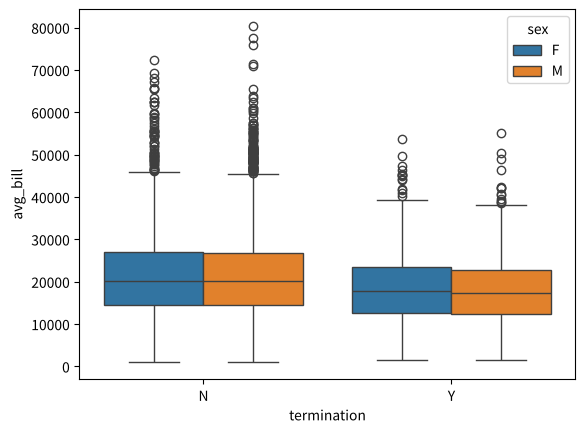

In [11]:
sns.boxplot(data=cust, x='termination', y='avg_bill', hue='sex')
plt.show()

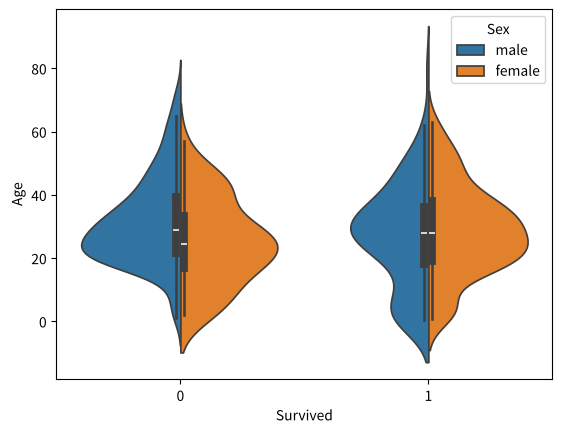

In [12]:
sns.violinplot(data=titanic, x='Survived', y='Age', hue='Sex', split=True)
plt.show()

---
## 4. 두 수치형 변수의 관계: `scatterplot`, `jointplot` ★

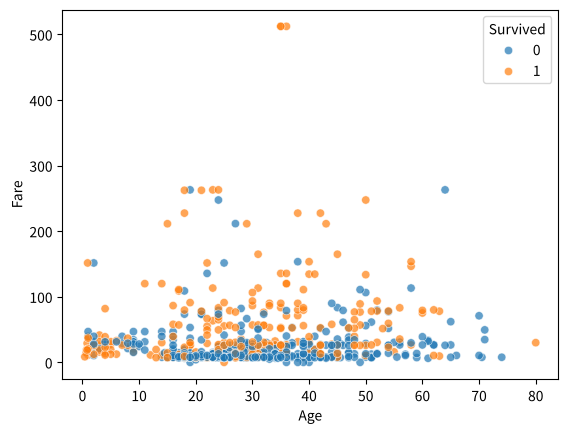

In [13]:
sns.scatterplot(data=titanic, x='Age', y='Fare', hue='Survived', alpha=0.7)
plt.show()

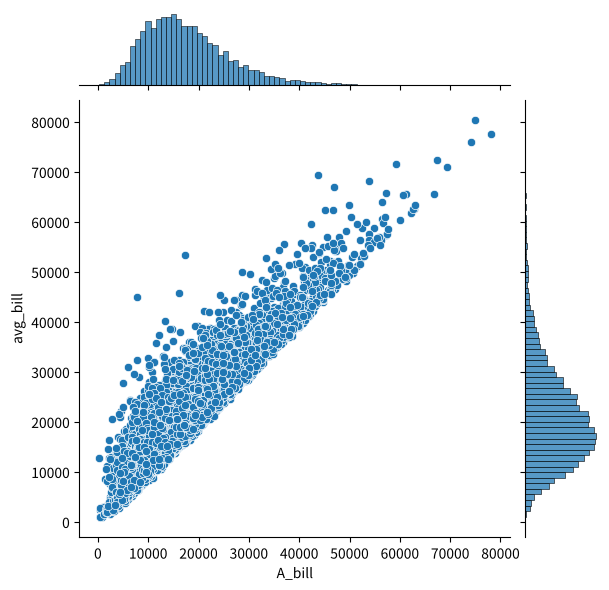

In [14]:
# jointplot: 산점도 + 각 축의 분포를 함께 (샘플 문항 회귀편 4번)
sns.jointplot(data=cust, x='A_bill', y='avg_bill')
plt.show()

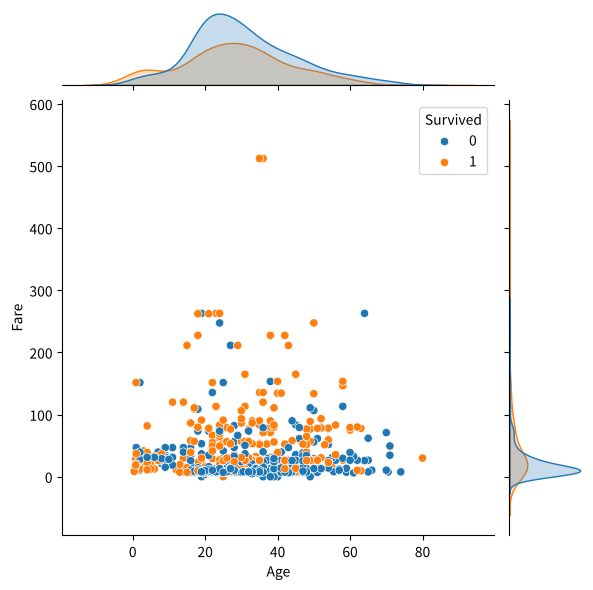

In [15]:
sns.jointplot(data=titanic, x='Age', y='Fare', hue='Survived')
plt.show()

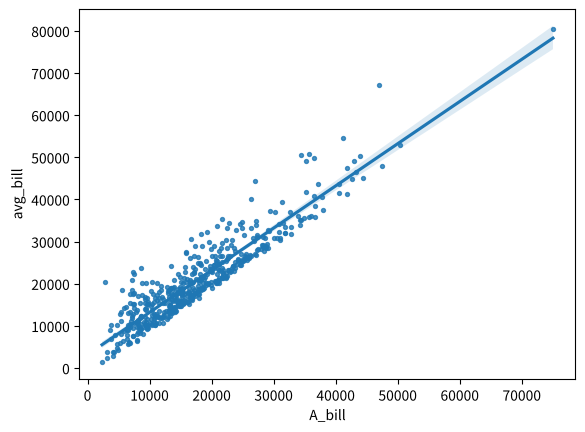

In [16]:
# regplot / lmplot: 회귀선 포함
sns.regplot(data=cust.sample(500, random_state=1), x='A_bill', y='avg_bill', scatter_kws={'s': 8})
plt.show()

---
## 5. 평균 비교: `barplot`, `pointplot`

`barplot`은 개수가 아니라 **y의 평균**(과 신뢰구간)을 막대로 그립니다. countplot과 구분하세요!

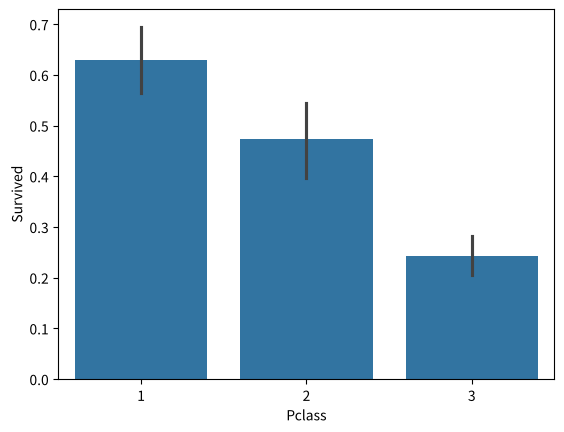

In [17]:
sns.barplot(data=titanic, x='Pclass', y='Survived')     # 등급별 생존율(평균)
plt.show()

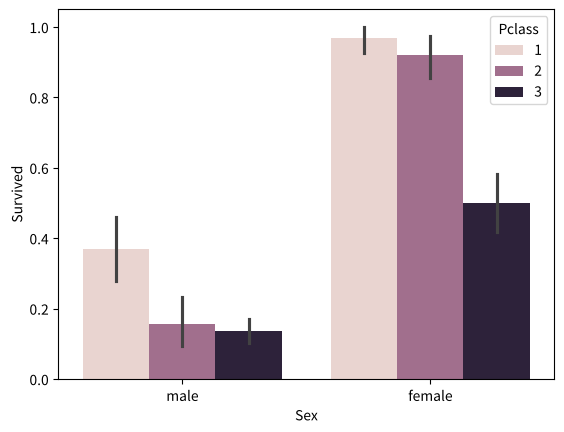

In [18]:
sns.barplot(data=titanic, x='Sex', y='Survived', hue='Pclass')
plt.show()

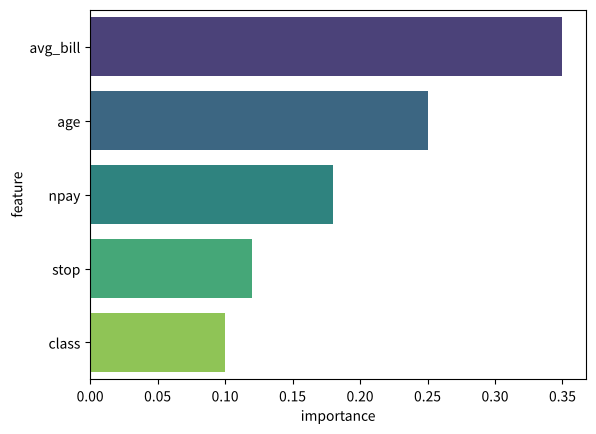

In [19]:
# 변수 중요도 막대그래프 (시험 11번 문항 유형) - 가로 막대
fi = pd.DataFrame({'feature': ['avg_bill', 'age', 'npay', 'stop', 'class'], 'importance': [0.35, 0.25, 0.18, 0.12, 0.10]})
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')
plt.show()

---
## 6. 상관관계: `heatmap` ★, `pairplot`

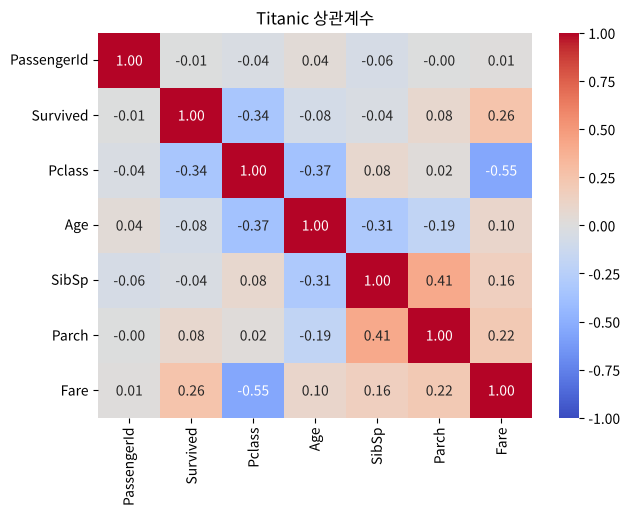

In [20]:
corr = titanic.select_dtypes(include='number').corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Titanic 상관계수')
plt.show()

In [21]:
# 타깃과의 상관계수만 정렬해서 보기
corr['Survived'].drop('Survived').sort_values()

Pclass        -0.338481
Age           -0.077221
SibSp         -0.035322
PassengerId   -0.005007
Parch          0.081629
Fare           0.257307
Name: Survived, dtype: float64

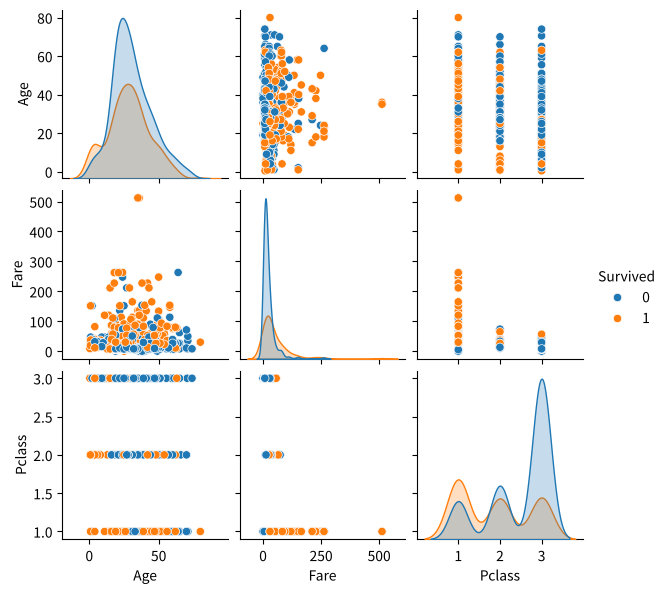

In [22]:
# pairplot: 모든 수치형 변수 쌍의 산점도 (시간이 걸리므로 컬럼을 제한)
sns.pairplot(titanic[['Age', 'Fare', 'Pclass', 'Survived']].dropna(), hue='Survived', height=2)
plt.show()

---
## 7. 시간 흐름: `lineplot`

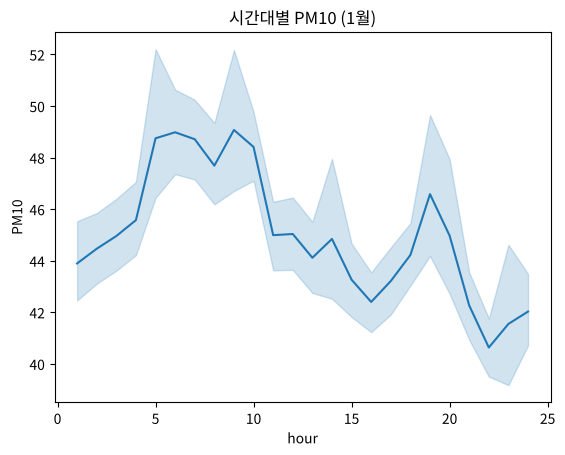

In [23]:
# 16번 미세먼지 실습 맛보기: 1월 데이터의 시간대별 평균 PM10
air = pd.read_csv('air_data_01.csv', encoding='cp949')
air['hour'] = air['측정일시'] % 100
sns.lineplot(data=air, x='hour', y='PM10')
plt.title('시간대별 PM10 (1월)')
plt.show()

---
## 8. ★ subplots에 seaborn 그래프 배치: `ax=` 파라미터

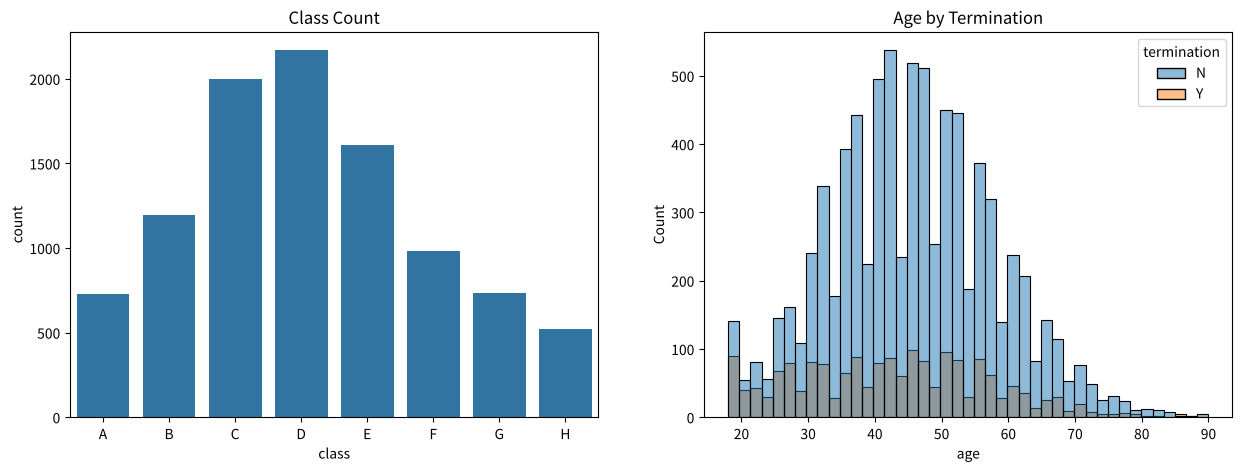

In [24]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

sns.countplot(data=cust, x='class', order=sorted(cust['class'].unique()), ax=axes[0])
sns.histplot(data=cust, x='age', hue='termination', ax=axes[1])

axes[0].set_title('Class Count')
axes[1].set_title('Age by Termination')
plt.show()

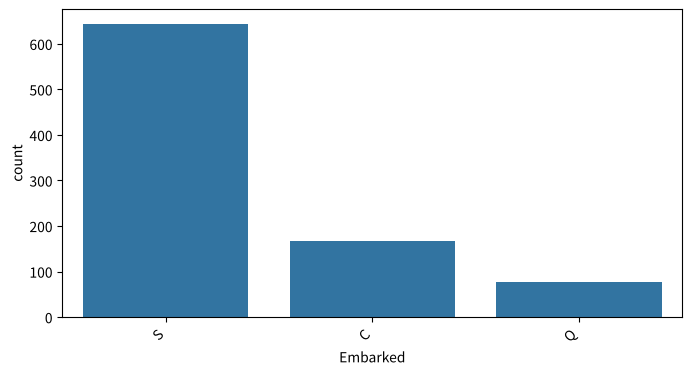

In [25]:
# x축 라벨 회전 (라벨이 길 때)
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=titanic, x='Embarked', ax=ax)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

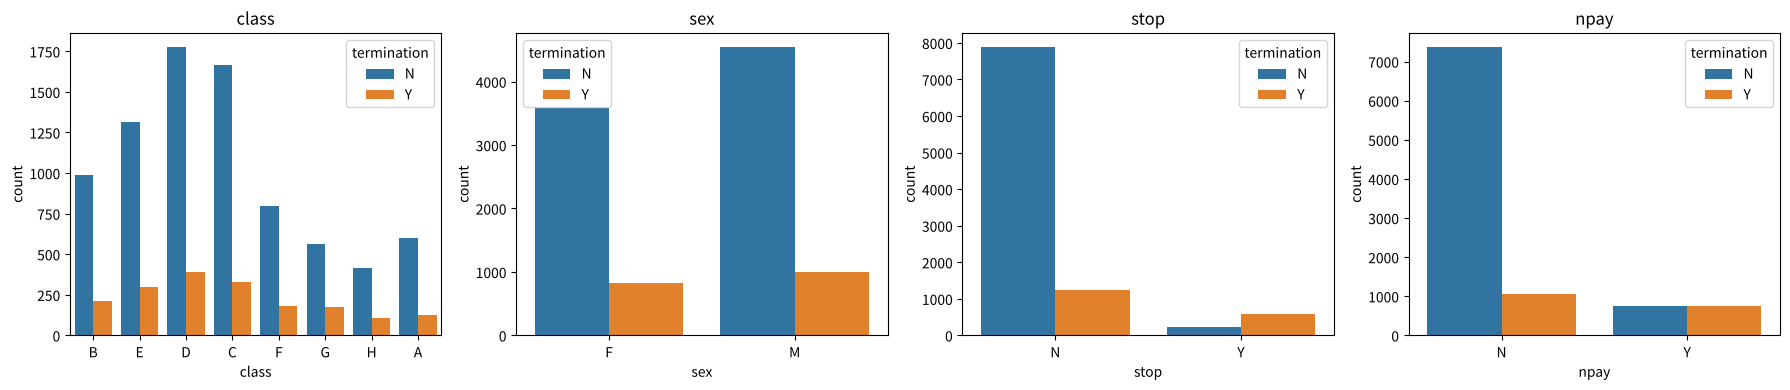

In [26]:
# 반복문으로 여러 컬럼 한 번에
cols = ['class', 'sex', 'stop', 'npay']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols):
    sns.countplot(data=cust, x=col, hue='termination', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

---
## ✏️ 연습문제

**문제 1.** `cust`의 고객 등급(`class`) 분포를 countplot으로 그리고, 가장 고객이 많은 등급을 `답안1`에 저장하세요.

In [27]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 2.** `cust`에서 해지 여부(`termination`)별 평균 청구액(`avg_bill`) 분포를 boxplot으로 그리세요. X축은 `termination`, Y축은 `avg_bill`.

In [28]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 3.** 아래 코드의 빈칸을 채워, 왼쪽에는 `sex` countplot, 오른쪽에는 `termination`별 `age` histplot을 그리고 제목을 각각 `'Sex Count'`, `'Age Dist'`로 설정하세요. 빈칸 내용을 `답안3_1`, `답안3_2`, `답안3_3`에 저장하세요.
```python
fig, axes = plt.< blank3-1 >(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=cust, x='sex', ax=< blank3-2 >[0])
sns.histplot(data=cust, x='age', hue='termination', ax=< blank3-2 >[1])
axes[0].< blank3-3 >('Sex Count')
axes[1].< blank3-3 >('Age Dist')
plt.show()
```

In [29]:
# 아래 코드의 빈칸을 채우고 실행하세요.

**문제 4.** `cust`의 수치형 컬럼 상관계수를 heatmap으로 그리고(`annot=True`), `avg_bill`과 상관계수가 가장 높은 다른 컬럼명을 `답안4`에 저장하세요.

In [30]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 5.** jointplot으로 `A_bill`(X축)과 `B_bill`(Y축)의 관계를 그리세요.

In [31]:
# 여기에 답안코드를 작성하고 실행하세요.

---
## ✅ 정답 및 해설

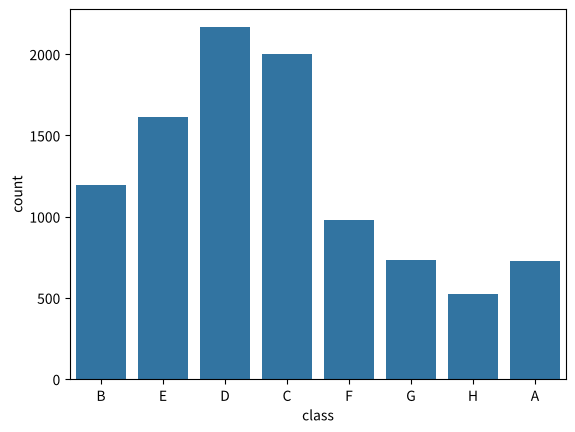

D


In [32]:
# 문제 1
sns.countplot(data=cust, x='class')
plt.show()
답안1 = cust['class'].value_counts().idxmax()
print(답안1)

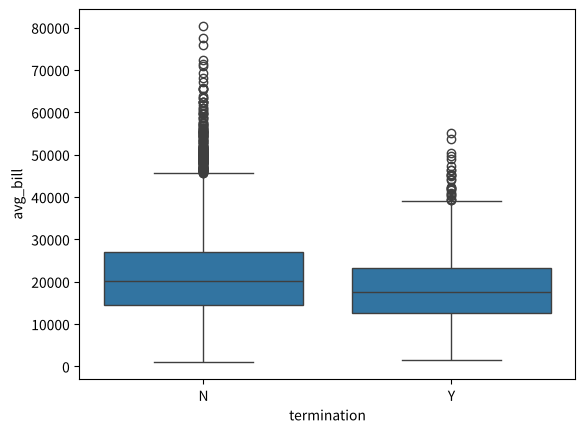

In [33]:
# 문제 2
sns.boxplot(data=cust, x='termination', y='avg_bill')
plt.show()

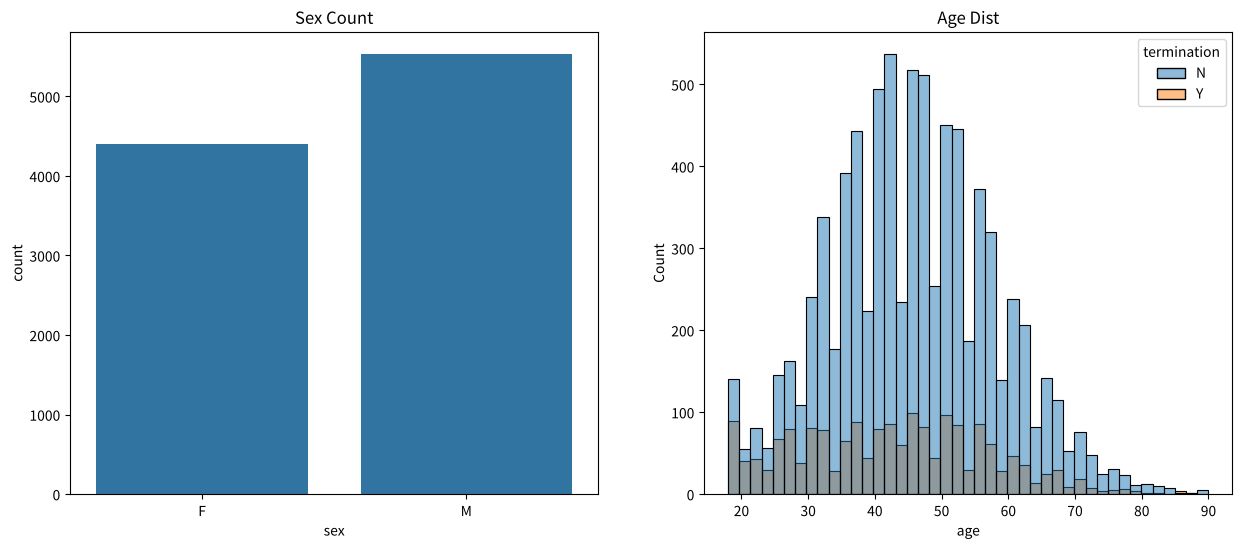

In [34]:
# 문제 3
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=cust, x='sex', ax=axes[0])
sns.histplot(data=cust, x='age', hue='termination', ax=axes[1])
axes[0].set_title('Sex Count')
axes[1].set_title('Age Dist')
plt.show()
답안3_1, 답안3_2, 답안3_3 = 'subplots', 'axes', 'set_title'

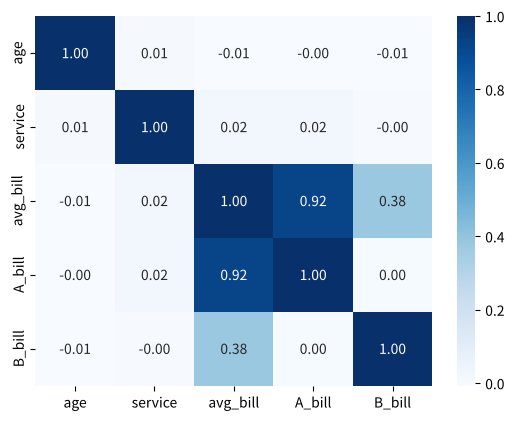

A_bill


In [35]:
# 문제 4
corr = cust.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues')
plt.show()
답안4 = corr['avg_bill'].drop('avg_bill').idxmax()
print(답안4)

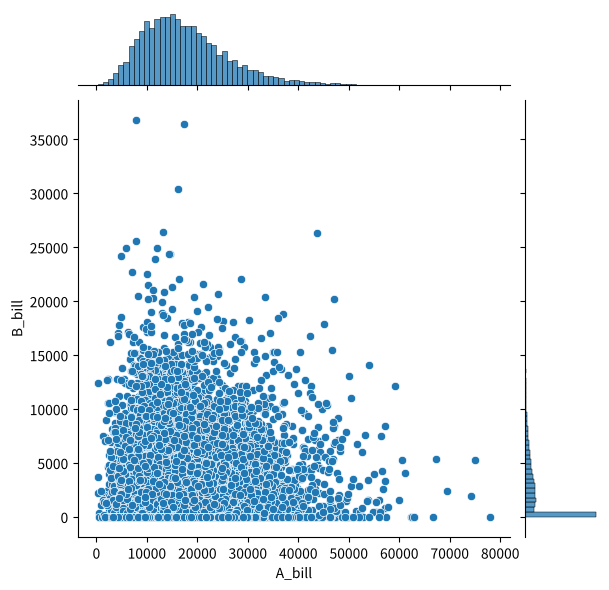

In [36]:
# 문제 5
sns.jointplot(data=cust, x='A_bill', y='B_bill')
plt.show()